### Zadania

Celem listy jest zbadanie działania metod binaryzacji obrazów w skali szarości i kolorowych. Dążymy do wyobrębnienia obiektów znajdujących się na podanych obrazach, tzn. uzyskania separacji obiektów od tła, a także oddzielenia poszczególnych obiektów. Natomiast samo osiągnięcie "jakiegoś" wyniku ([`cv2.threshold`](https://docs.opencv.org/3.4/d7/d1b/group__imgproc__misc.html#gae8a4a146d1ca78c626a53577199e9c57) odpalone, próg wybrany "z palca", _coś tam_ wychodzi, wynik wyświetlony) to co najwyżej połowa sukcesu i oceny. Ważne jest przeprowadzenie eksperymentów wyjaśniających dobór parametrów.

In [125]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

MAX_VALUE = 255
NUM_LEVELS = 256
OTSU_AUTO = 0
MIN_OBJECT_AREA = 500

COLORS = {
    "clean": "tab:blue",
    "noisy": "tab:orange",
    "threshold": "tab:red",
    "median": "tab:green",
    "gaussian": "tab:purple",
    "H": "tab:brown",
    "S": "tab:cyan",
    "V": "black",
    "expected": "tab:gray",
}

##### Zad. 1: Monety szare

Dane są dwa czarno-białe obrazy monet, `monety_szare` oraz `monety_szare_szum`, z których drugi zawiera pewien poziom zakłóceń. Dokonaj binaryzacji tych obrazów za pomocą progowania.  
Jak wartość progu wpływa na wyniki?  
Jaki wpływ mają zakłócenia w drugim obrazie? Zastosuj wybraną metodę odszumiania i przeanalizuj efekty.

In [126]:
coins_gray = cv2.imread('data/coins_gray.bmp', cv2.IMREAD_GRAYSCALE)
coins_gray_noisy = cv2.imread('data/coins_gray_noisy.bmp', cv2.IMREAD_GRAYSCALE)

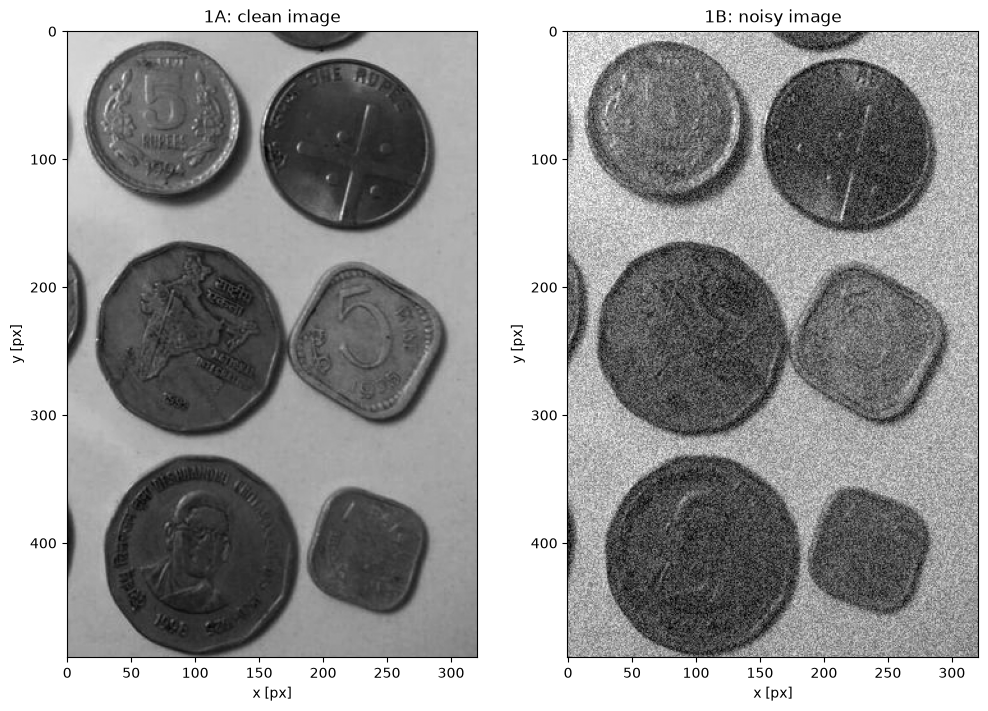

In [127]:
def show_image(ax, img, title):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.set_xlabel("x [px]")
    ax.set_ylabel("y [px]")


fig, axes = plt.subplots(1, 2, figsize=(10, 7), constrained_layout=True)
show_image(axes[0], coins_gray, "1A: clean image")
show_image(axes[1], coins_gray_noisy, "1B: noisy image")
plt.show()

Solution 1A:

In [128]:
def binarize(img, threshold):
    _, mask = cv2.threshold(img, threshold, MAX_VALUE, cv2.THRESH_BINARY_INV)
    return mask


def binarize_otsu(img):
    threshold, mask = cv2.threshold(img, OTSU_AUTO, MAX_VALUE, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    return threshold, mask


def count_objects(mask):
    _, _, stats, _ = cv2.connectedComponentsWithStats(mask)
    return int((stats[1:, cv2.CC_STAT_AREA] >= MIN_OBJECT_AREA).sum())

Method 1: threshold from one random background pixel (T = pixel - margin)

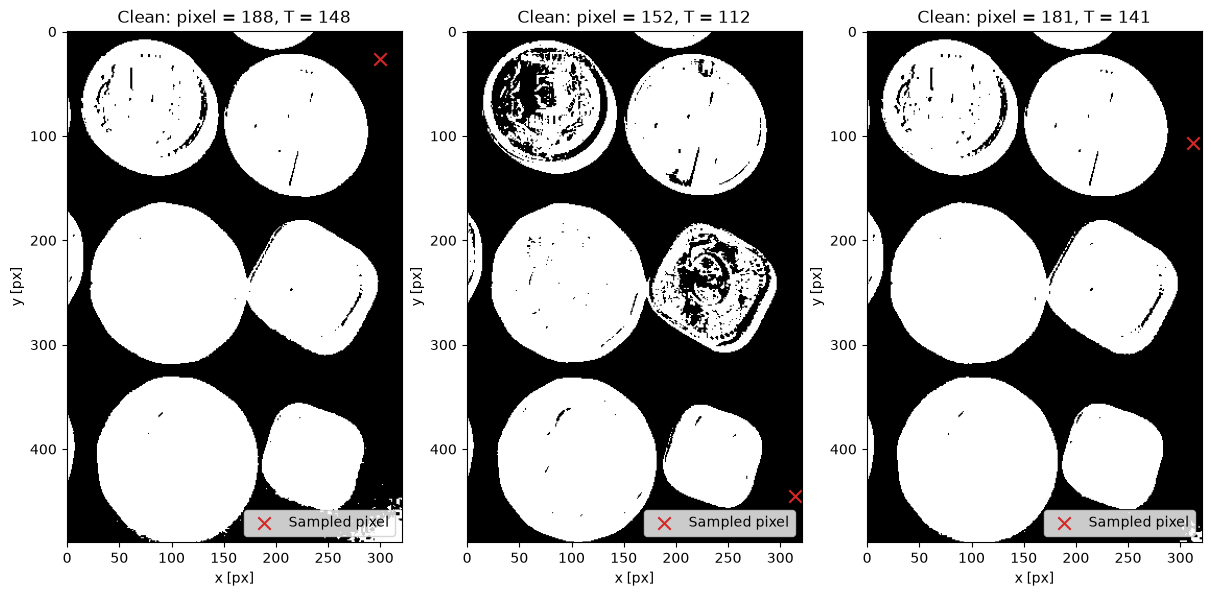

In [129]:
BG_MARGIN = 40
N_BG_POINTS = 3
SEED = 123
BG_X_MIN = 300

height, width = coins_gray.shape
rng = np.random.default_rng(SEED)
points = np.column_stack([rng.integers(BG_X_MIN, width, N_BG_POINTS), rng.integers(0, height, N_BG_POINTS)])


def show_background_thresholds(img, label):
    fig, axes = plt.subplots(1, N_BG_POINTS, figsize=(12, 6), constrained_layout=True)
    for ax, (x, y) in zip(axes, points):
        threshold = int(img[y, x]) - BG_MARGIN
        show_image(ax, binarize(img, threshold), f"{label}: pixel = {img[y, x]}, T = {threshold}")
        ax.scatter(x, y, color=COLORS["threshold"], marker="x", s=80, label="Sampled pixel")
        ax.legend(loc="lower right")
    plt.show()


show_background_thresholds(coins_gray, "Clean")

Method 2: threshold from the histogram (Otsu)

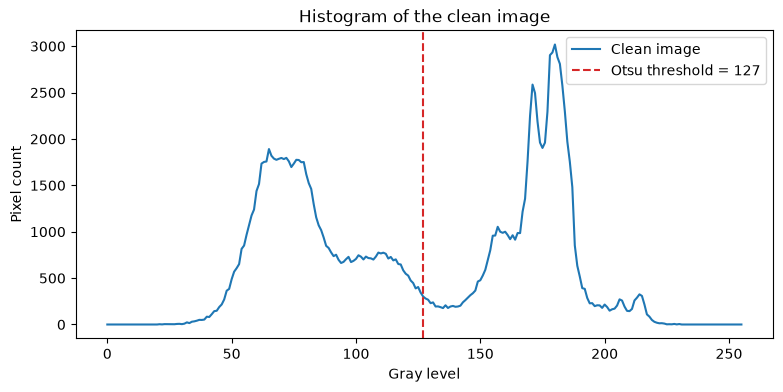

In [130]:
otsu_clean, mask_otsu_clean = binarize_otsu(coins_gray)
hist_clean = np.bincount(coins_gray.ravel(), minlength=NUM_LEVELS)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(hist_clean, color=COLORS["clean"], label="Clean image")
ax.axvline(otsu_clean, color=COLORS["threshold"], linestyle="--", label=f"Otsu threshold = {otsu_clean:.0f}")
ax.set_title("Histogram of the clean image")
ax.set_xlabel("Gray level")
ax.set_ylabel("Pixel count")
ax.legend()
plt.show()

Effect of the threshold value

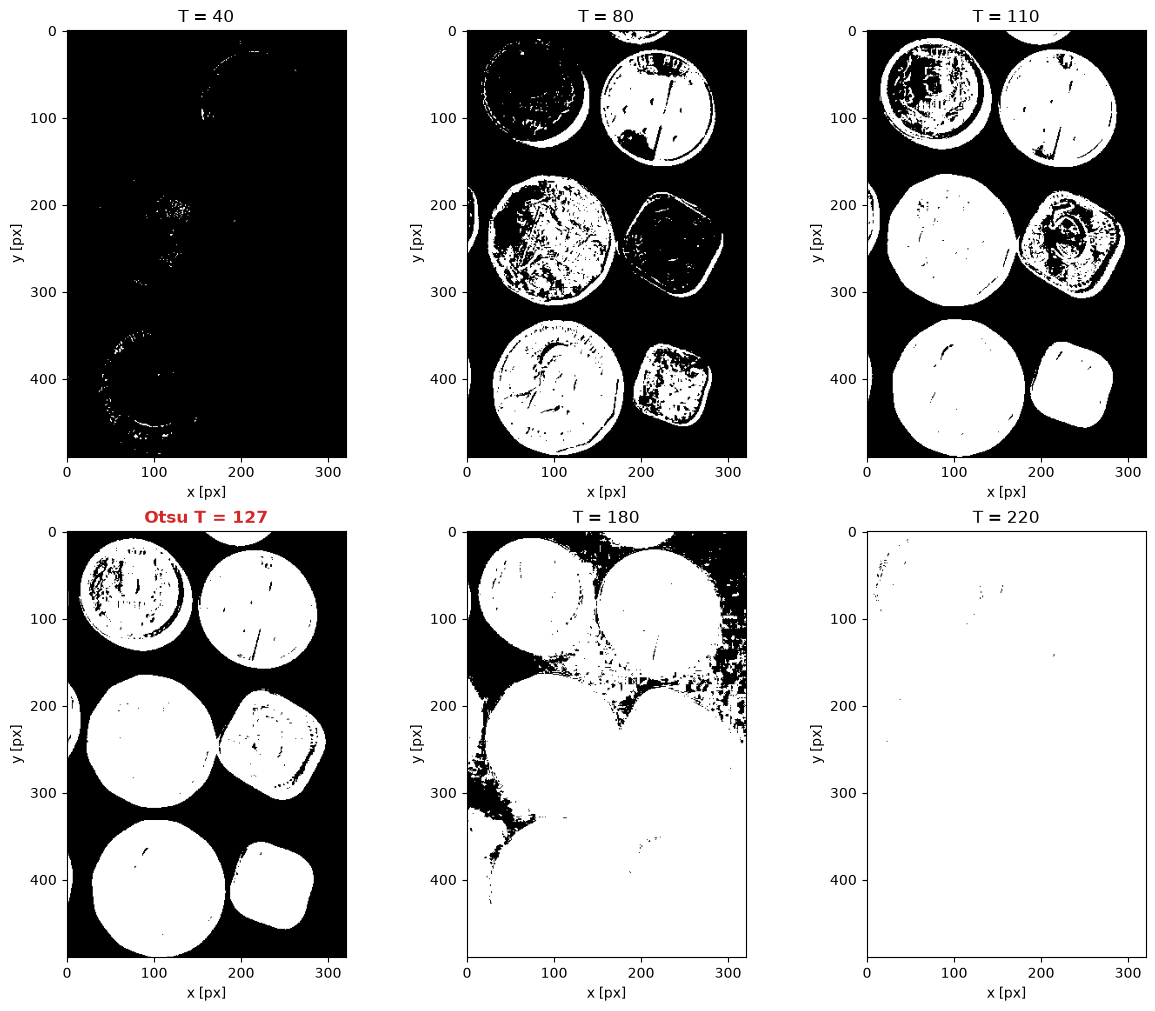

In [131]:
THRESHOLDS = [40, 80, 110, otsu_clean, 180, 220]

fig, axes = plt.subplots(2, 3, figsize=(12, 10), constrained_layout=True)
for ax, threshold in zip(axes.ravel(), THRESHOLDS):
    is_otsu = threshold == otsu_clean
    show_image(ax, binarize(coins_gray, threshold), f"{'Otsu ' if is_otsu else ''}T = {threshold:.0f}")
    if is_otsu:
        ax.set_title(ax.get_title(), color=COLORS["threshold"], fontweight="bold")
plt.show()

Number of objects vs threshold. Objects are connected white regions of the mask with area >= 500 px (`cv2.connectedComponentsWithStats`); a good threshold gives a stable count over a range of T.

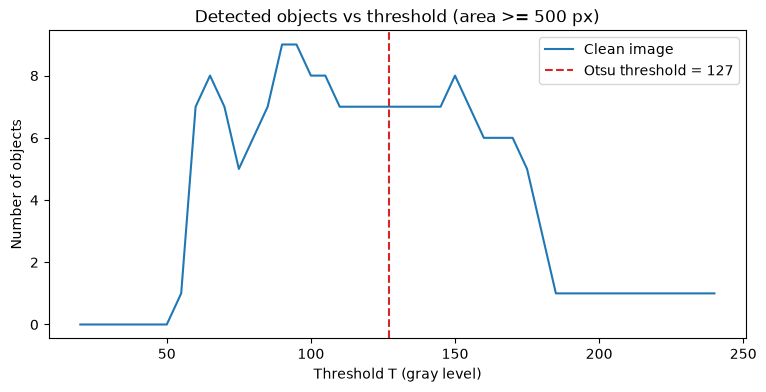

In [132]:
THRESH_MIN, THRESH_MAX, THRESH_STEP = 20, 240, 5
EXPECTED_OBJECTS = 8
sweep = np.arange(THRESH_MIN, THRESH_MAX + 1, THRESH_STEP)
objects_clean = [count_objects(binarize(coins_gray, t)) for t in sweep]

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(sweep, objects_clean, color=COLORS["clean"], label="Clean image")
ax.axhline(EXPECTED_OBJECTS, color=COLORS["expected"], linestyle=":", label=f"Expected = {EXPECTED_OBJECTS} (6 coins + 2 border fragments)")
ax.axvline(otsu_clean, color=COLORS["threshold"], linestyle="--", label=f"Otsu threshold = {otsu_clean:.0f}")
ax.set_title(f"Detected objects vs threshold (area >= {MIN_OBJECT_AREA} px)")
ax.set_xlabel("Threshold T (gray level)")
ax.set_ylabel("Number of objects")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

Coins are darker than the background, so `THRESH_BINARY_INV` makes them white. Below T = 60 almost nothing is selected, above T = 150 the bright background leaks in. For T = 110-145 the count is stable but equals 7, not the expected 8: at these thresholds the large coin and the square coin touch and merge into one object. Lower T separates them but breaks the coin interiors, so a threshold alone is not enough.

Separating touching coins: morphological opening of the Otsu mask

In [ ]:
OPEN_KERNEL_SIZE = 9

open_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (OPEN_KERNEL_SIZE, OPEN_KERNEL_SIZE))
mask_opened = cv2.morphologyEx(mask_otsu_clean, cv2.MORPH_OPEN, open_kernel)

fig, axes = plt.subplots(1, 2, figsize=(12, 7), constrained_layout=True)
show_image(axes[0], mask_otsu_clean, f"Otsu mask, objects = {count_objects(mask_otsu_clean)}")
show_image(axes[1], mask_opened, f"After opening {OPEN_KERNEL_SIZE}x{OPEN_KERNEL_SIZE}, objects = {count_objects(mask_opened)}")
plt.show()

Solution 1B:

Method 1 on the noisy image (same pixels, same margin)

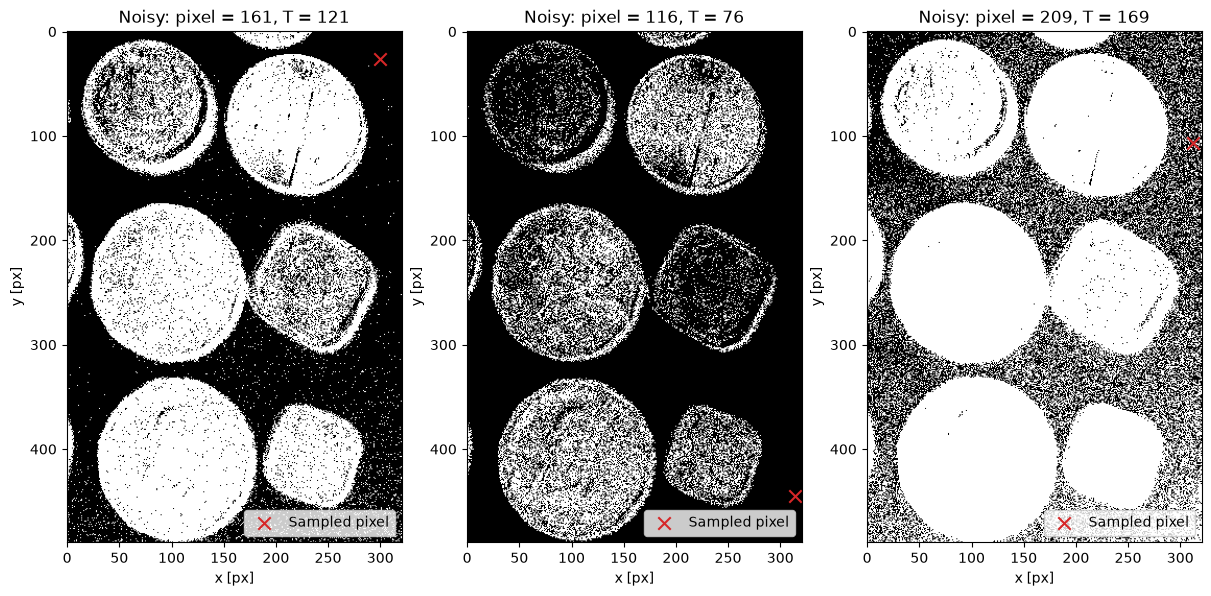

In [133]:
show_background_thresholds(coins_gray_noisy, "Noisy")

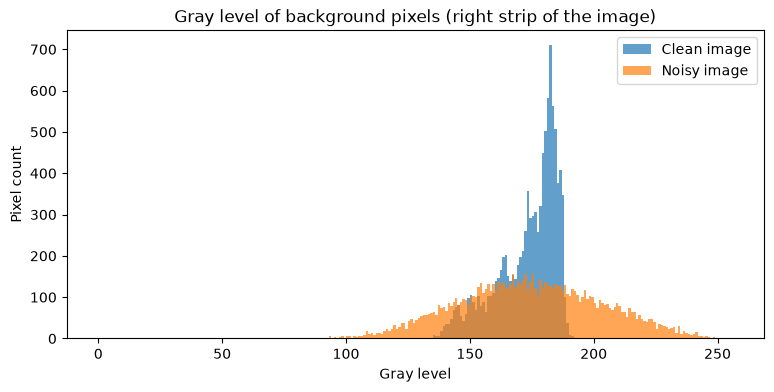

In [134]:
clean_values = coins_gray[:, BG_X_MIN:].ravel()
noisy_values = coins_gray_noisy[:, BG_X_MIN:].ravel()

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(NUM_LEVELS + 1)
ax.hist(clean_values, bins=bins, color=COLORS["clean"], alpha=0.7, label="Clean image")
ax.hist(noisy_values, bins=bins, color=COLORS["noisy"], alpha=0.7, label="Noisy image")
ax.set_title("Gray level of background pixels (right strip of the image)")
ax.set_xlabel("Gray level")
ax.set_ylabel("Pixel count")
ax.legend()
plt.show()

Method 2 on the noisy image: histogram and Otsu

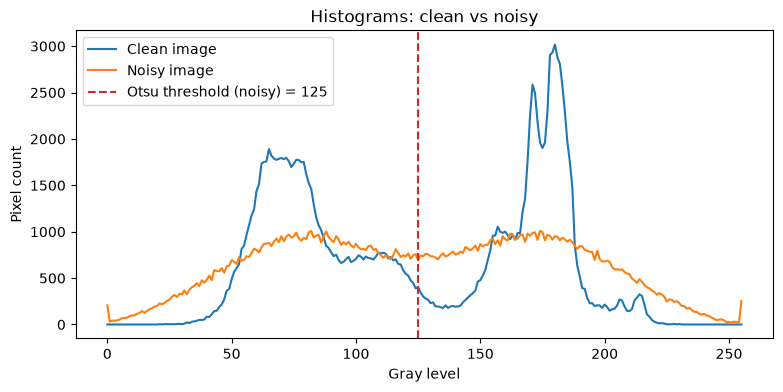

In [135]:
otsu_noisy, mask_otsu_noisy = binarize_otsu(coins_gray_noisy)
hist_noisy = np.bincount(coins_gray_noisy.ravel(), minlength=NUM_LEVELS)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(hist_clean, color=COLORS["clean"], label="Clean image")
ax.plot(hist_noisy, color=COLORS["noisy"], label="Noisy image")
ax.axvline(otsu_noisy, color=COLORS["threshold"], linestyle="--", label=f"Otsu threshold (noisy) = {otsu_noisy:.0f}")
ax.set_title("Histograms: clean vs noisy")
ax.set_xlabel("Gray level")
ax.set_ylabel("Pixel count")
ax.legend()
plt.show()

Denoise first, then threshold

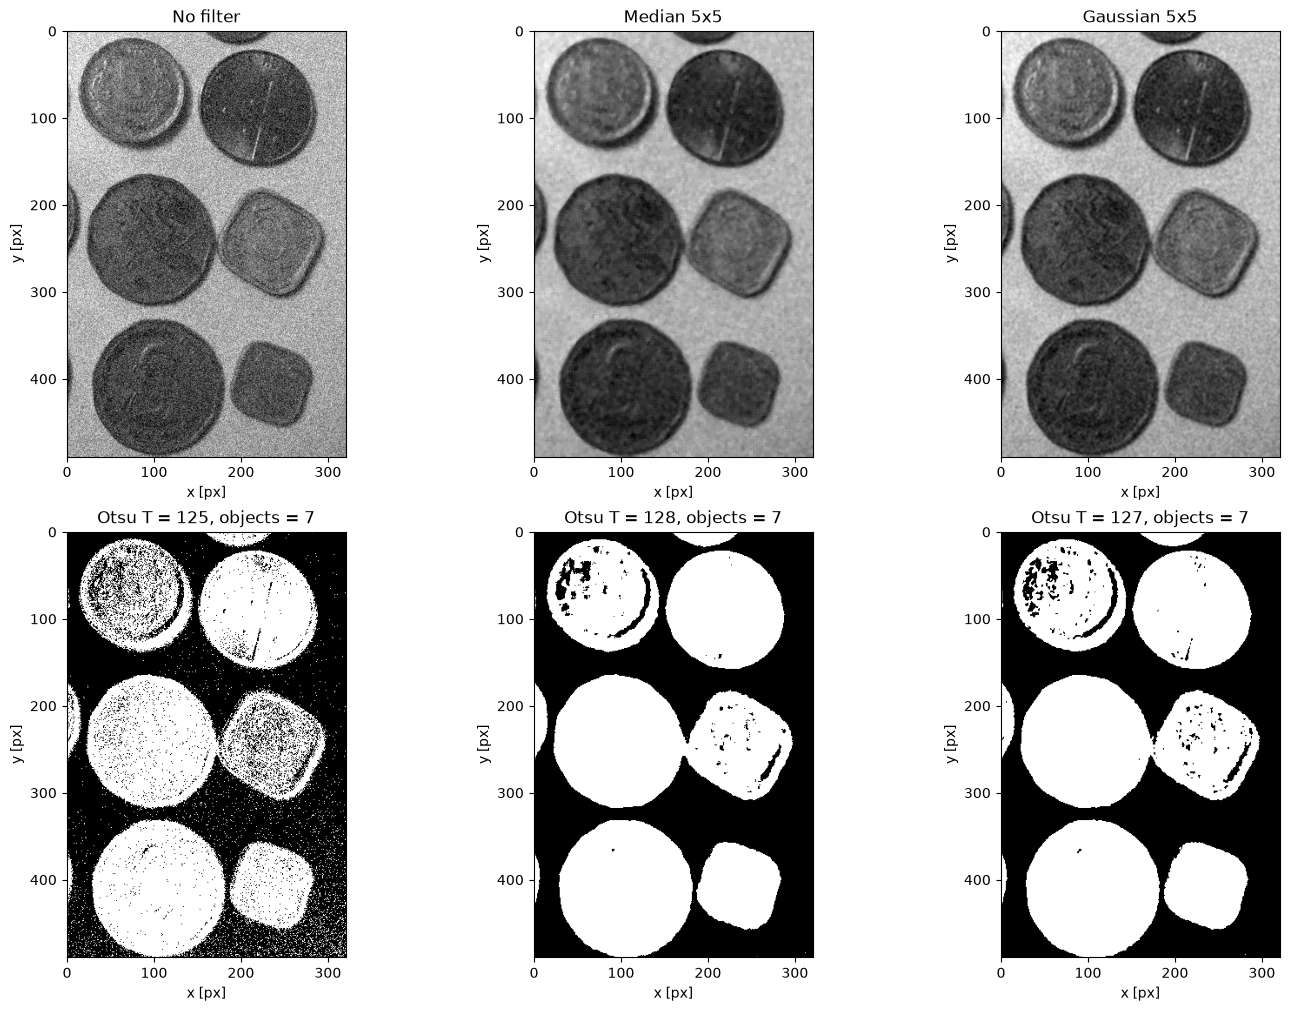

In [136]:
KERNEL_SIZE = 5

median_noisy = cv2.medianBlur(coins_gray_noisy, KERNEL_SIZE)
gaussian_noisy = cv2.GaussianBlur(coins_gray_noisy, (KERNEL_SIZE, KERNEL_SIZE), 0)

variants = {
    "No filter": coins_gray_noisy,
    f"Median {KERNEL_SIZE}x{KERNEL_SIZE}": median_noisy,
    f"Gaussian {KERNEL_SIZE}x{KERNEL_SIZE}": gaussian_noisy,
}

fig, axes = plt.subplots(2, 3, figsize=(14, 10), constrained_layout=True)
for col, (name, img) in enumerate(variants.items()):
    threshold, mask = binarize_otsu(img)
    show_image(axes[0, col], img, name)
    show_image(axes[1, col], mask, f"Otsu T = {threshold:.0f}, objects = {count_objects(mask)}")
plt.show()

Threshold value vs filter on the noisy image

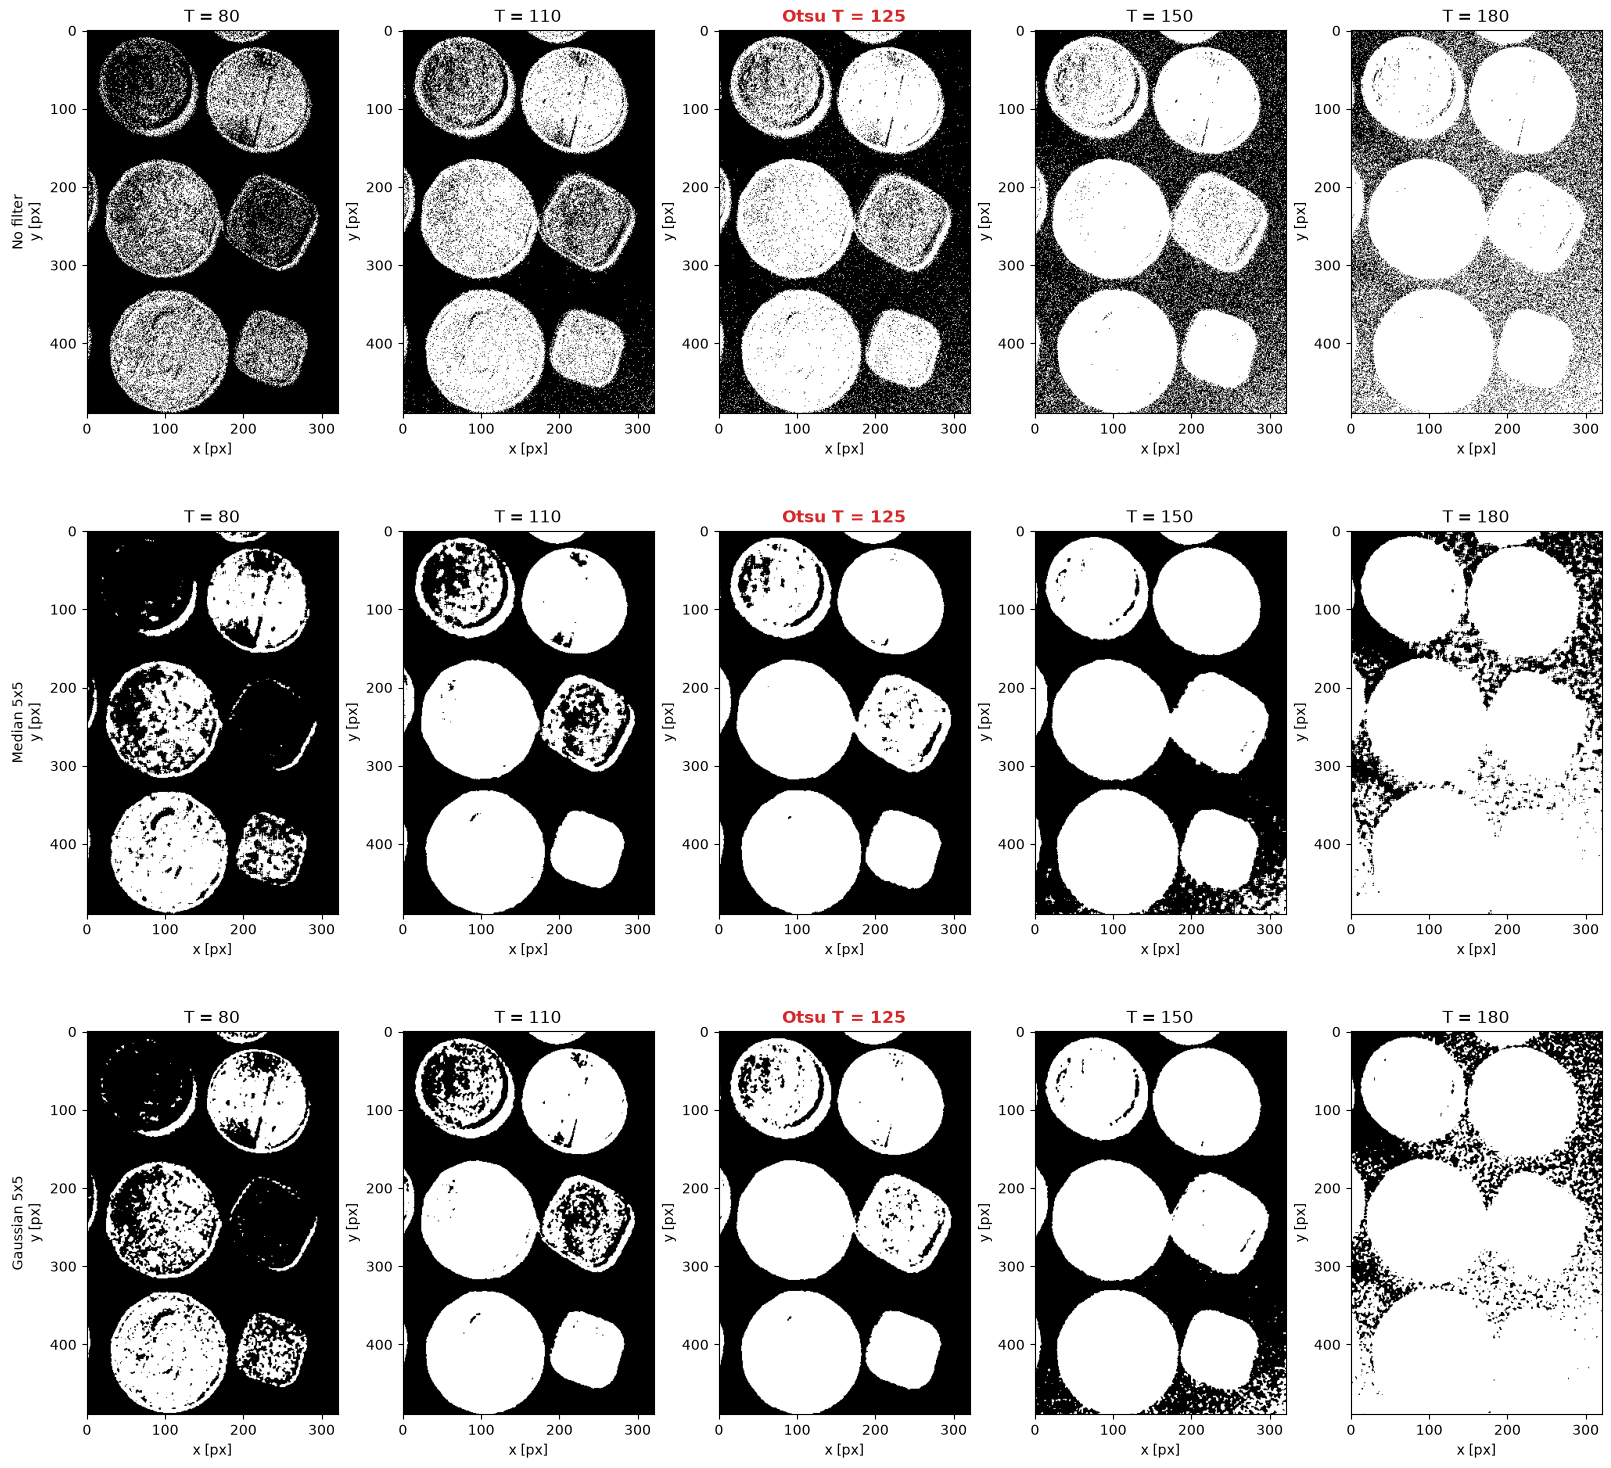

In [137]:
THRESHOLDS_NOISY = [80, 110, otsu_noisy, 150, 180]

fig, axes = plt.subplots(len(variants), len(THRESHOLDS_NOISY), figsize=(16, 15), constrained_layout=True)
for row, (name, img) in enumerate(variants.items()):
    for col, threshold in enumerate(THRESHOLDS_NOISY):
        ax = axes[row, col]
        is_otsu = threshold == otsu_noisy
        show_image(ax, binarize(img, threshold), f"{'Otsu ' if is_otsu else ''}T = {threshold:.0f}")
        if is_otsu:
            ax.set_title(ax.get_title(), color=COLORS["threshold"], fontweight="bold")
        if col == 0:
            ax.set_ylabel(f"{name}\ny [px]")
plt.show()

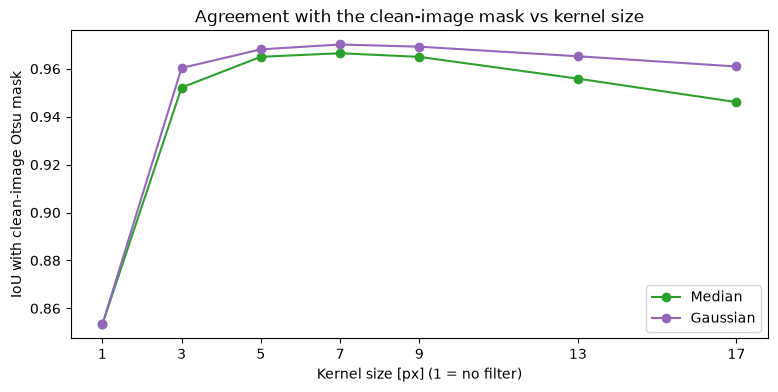

In [138]:
KERNEL_SIZES = [1, 3, 5, 7, 9, 13, 17]

def mask_iou(mask_a, mask_b):
    a, b = mask_a > 0, mask_b > 0
    return (a & b).sum() / (a | b).sum()


def iou_for_kernel(blur, size):
    _, mask = binarize_otsu(blur(coins_gray_noisy, size))
    return mask_iou(mask, mask_otsu_clean)


iou_median = [iou_for_kernel(cv2.medianBlur, k) for k in KERNEL_SIZES]
iou_gaussian = [iou_for_kernel(lambda img, k: cv2.GaussianBlur(img, (k, k), 0), k) for k in KERNEL_SIZES]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(KERNEL_SIZES, iou_median, marker="o", color=COLORS["median"], label="Median")
ax.plot(KERNEL_SIZES, iou_gaussian, marker="o", color=COLORS["gaussian"], label="Gaussian")
ax.set_title("Agreement with the clean-image mask vs kernel size")
ax.set_xlabel("Kernel size [px] (1 = no filter)")
ax.set_ylabel("IoU with clean-image Otsu mask")
ax.set_xticks(KERNEL_SIZES)
ax.legend()
plt.show()

Noise breaks the bimodal histogram, so Otsu on the raw image leaves speckles in both coins and background. Both filters fix this; Gaussian is slightly better (IoU about 0.97 at 7x7 vs 0.967 for median). Larger kernels blur the coin edges and IoU falls, so 5x5 to 7x7 is the sweet spot. Median keeps edges sharper, Gaussian keeps interiors smoother.

##### Zad. 2: Monety kolorowe

Na podobnej zasadzie dokonaj binaryzacji poniższego obrazu kolorowego.  
Skorzystaj z modelu barw HSV. Uzasadnij dobór kanału oraz progu binaryzacji.

In [ ]:
coins_color = cv2.imread('data/coins_color.bmp')
coins_color_noisy = cv2.imread('data/coins_color_noisy.bmp')

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 11), constrained_layout=True)
for ax, img, title in zip(axes, [coins_color, coins_color_noisy], ["Clean image", "Noisy image"]):
    show_image(ax, cv2.cvtColor(img, cv2.COLOR_BGR2RGB), title)
plt.show()

Solution 2:

HSV channels

In [ ]:
hsv_clean = cv2.cvtColor(coins_color, cv2.COLOR_BGR2HSV)
CHANNELS = {"H": "Hue (H)", "S": "Saturation (S)", "V": "Value (V)"}

fig, axes = plt.subplots(3, 1, figsize=(10, 14), constrained_layout=True)
for ax, (index, (key, title)) in zip(axes, enumerate(CHANNELS.items())):
    image = ax.imshow(hsv_clean[..., index], cmap="gray")
    ax.set_title(title)
    ax.set_xlabel("x [px]")
    ax.set_ylabel("y [px]")
    fig.colorbar(image, ax=ax, label="Channel value")
plt.show()

Histograms of the channels with Otsu thresholds

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for ax, (index, (key, title)) in zip(axes, enumerate(CHANNELS.items())):
    channel = hsv_clean[..., index]
    otsu_channel, _ = cv2.threshold(channel, OTSU_AUTO, MAX_VALUE, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    ax.plot(np.bincount(channel.ravel(), minlength=NUM_LEVELS), color=COLORS[key], label="Histogram")
    ax.axvline(otsu_channel, color=COLORS["threshold"], linestyle="--", label=f"Otsu T = {otsu_channel:.0f}")
    ax.set_yscale("log")
    ax.set_title(title)
    ax.set_xlabel("Channel value")
    ax.set_ylabel("Pixel count (log scale)")
    ax.legend()
plt.show()

Channel choice: number of objects vs threshold (S: pixel < T, V: pixel > T)

In [ ]:
EXPECTED_COINS = 20
S_INDEX, V_INDEX = 1, 2
SWEEP = np.arange(0, MAX_VALUE + 1, THRESH_STEP)


def channel_mask(img, index, threshold, below=True):
    channel = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)[..., index]
    mode = cv2.THRESH_BINARY_INV if below else cv2.THRESH_BINARY
    _, mask = cv2.threshold(channel, threshold, MAX_VALUE, mode)
    return mask


counts_s = [count_objects(channel_mask(coins_color, S_INDEX, t, below=True)) for t in SWEEP]
counts_v = [count_objects(channel_mask(coins_color, V_INDEX, t, below=False)) for t in SWEEP]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(SWEEP, counts_s, color=COLORS["S"], label="Saturation (S)")
ax.plot(SWEEP, counts_v, color=COLORS["V"], label="Value (V)")
ax.axhline(EXPECTED_COINS, color=COLORS["expected"], linestyle=":", label=f"Coins in image = {EXPECTED_COINS}")
ax.set_title("Detected objects vs threshold (clean image)")
ax.set_xlabel("Threshold T (channel value)")
ax.set_ylabel("Number of objects")
ax.legend()
plt.show()

Masks: Otsu on S, chosen T on S, Otsu on V

In [ ]:
S_THRESHOLD = 180

otsu_s, mask_s_otsu = cv2.threshold(hsv_clean[..., S_INDEX], OTSU_AUTO, MAX_VALUE, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
otsu_v, mask_v_otsu = cv2.threshold(hsv_clean[..., V_INDEX], OTSU_AUTO, MAX_VALUE, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
mask_s_chosen = channel_mask(coins_color, S_INDEX, S_THRESHOLD)

masks = {
    f"S < Otsu ({otsu_s:.0f})": mask_s_otsu,
    f"S < {S_THRESHOLD} (chosen)": mask_s_chosen,
    f"V > Otsu ({otsu_v:.0f})": mask_v_otsu,
}
fig, axes = plt.subplots(3, 1, figsize=(10, 14), constrained_layout=True)
for ax, (name, mask) in zip(axes, masks.items()):
    show_image(ax, mask, f"{name}, objects = {count_objects(mask)}")
plt.show()

Hue is useless here: silver coins have almost no saturation, so their hue is undefined, and the dark red background sits at hue 0 (wraps around). Value is useless because the background is a brightness gradient. Saturation separates cleanly: the background is saturated (about 240) while all coins are below about 150. The object count is stable at 20 for T = 145-225 and Otsu on S (131) lies below this plateau, so T = 180 (middle of the plateau) is used instead.

Przetestuj opracowany powyżej algorytm na poniższym obrazie z wyraźnym zaszumieniem. Co się zmienia i dlaczego? Uzupełnij potok przetwarzania o odszumianie.

Noisy image: same pipeline without and with denoising (applied before the HSV conversion)

In [ ]:
def color_pipeline(img, kernel_size=None, blur=cv2.medianBlur):
    if kernel_size:
        img = blur(img, kernel_size)
    return channel_mask(img, S_INDEX, S_THRESHOLD)


pipelines = {
    "No filter": color_pipeline(coins_color_noisy),
    f"Median {KERNEL_SIZE}x{KERNEL_SIZE}": color_pipeline(coins_color_noisy, KERNEL_SIZE),
    f"Gaussian {KERNEL_SIZE}x{KERNEL_SIZE}": color_pipeline(
        coins_color_noisy, KERNEL_SIZE, lambda img, k: cv2.GaussianBlur(img, (k, k), 0)
    ),
}
fig, axes = plt.subplots(3, 1, figsize=(10, 14), constrained_layout=True)
for ax, (name, mask) in zip(axes, pipelines.items()):
    show_image(ax, mask, f"{name}: objects = {count_objects(mask)}, IoU with clean = {mask_iou(mask, mask_s_chosen):.3f}")
plt.show()

In [ ]:
counts_noisy = [count_objects(channel_mask(coins_color_noisy, S_INDEX, t)) for t in SWEEP]
counts_noisy_median = [
    count_objects(channel_mask(cv2.medianBlur(coins_color_noisy, KERNEL_SIZE), S_INDEX, t)) for t in SWEEP
]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(SWEEP, counts_s, color=COLORS["clean"], label="Clean")
ax.plot(SWEEP, counts_noisy, color=COLORS["noisy"], label="Noisy, no filter")
ax.plot(SWEEP, counts_noisy_median, color=COLORS["median"], label=f"Noisy, median {KERNEL_SIZE}x{KERNEL_SIZE}")
ax.axvline(S_THRESHOLD, color=COLORS["threshold"], linestyle="--", label=f"Chosen T = {S_THRESHOLD}")
ax.axhline(EXPECTED_COINS, color=COLORS["expected"], linestyle=":", label=f"Coins in image = {EXPECTED_COINS}")
ax.set_title("Detected objects vs threshold on the S channel")
ax.set_xlabel("Threshold T (S channel value)")
ax.set_ylabel("Number of objects")
ax.legend()
plt.show()

Denoising before thresholding removes the speckles (IoU 0.875 -> 0.96) and widens the stable range of T. Median is marginally better than Gaussian. Without a filter the object count stays at 20 only because of the minimum-area rule; the mask itself is noisy.

##### Zad. 3: Tekst

W tym przypadku należy wyodrębnić litery od bardzo nierównomiernie oświetlonego tła. Skorzystaj z binaryzacji metodą Otsu. Zastosuj binaryzację w sposób lokalny (oknem przesuwnym). Jaki wpływ ma rozmiar okna na jakość binaryzacji? Jak przesuwać okno?

_(Pełna punktacja za zadanie wymaga własnoręcznej implementacji okna przesuwnego - samo Otsu możesz wziąć z OpenCV. Użycie zamiast tego_ `cv2.adaptiveThreshold` _liczone będzie jako pół zadania, ale jedynie po demonstracji zrozumienia tej metody.)_

In [ ]:
text = cv2.imread('data/text1.bmp', cv2.IMREAD_GRAYSCALE)

Solution 3:

Global Otsu under uneven lighting

In [ ]:
otsu_text, mask_text_global = binarize_otsu(text)
mask_text_global = cv2.bitwise_not(mask_text_global)

fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
show_image(axes[0], text, "Text image")
show_image(axes[1], mask_text_global, f"Global Otsu, T = {otsu_text:.0f}")
axes[2].plot(text.mean(axis=0), color=COLORS["clean"])
axes[2].set_title("Mean gray level along the image width")
axes[2].set_xlabel("x [px]")
axes[2].set_ylabel("Mean gray level")
plt.show()

Local Otsu with a sliding window (own implementation)

In [ ]:
STEP_DIVISOR = 4
MIN_STEP = 4
MIN_RELATIVE_STD = 0.12


def local_otsu(img, window, step, min_rel_std=MIN_RELATIVE_STD):
    """Otsu threshold of a window centred on every step x step cell; windows with low relative contrast count as background."""
    height, width = img.shape
    half = window // 2
    padded = cv2.copyMakeBorder(img, window, window, window, window, cv2.BORDER_REFLECT)
    mask = np.zeros_like(img)
    for y in range(0, height, step):
        for x in range(0, width, step):
            top = y + step // 2 - half + window
            left = x + step // 2 - half + window
            patch = padded[top:top + window, left:left + window]
            threshold, _ = cv2.threshold(patch, OTSU_AUTO, MAX_VALUE, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
            if patch.std() < min_rel_std * patch.mean():
                threshold = 0
            mask[y:y + step, x:x + step] = np.where(img[y:y + step, x:x + step] > threshold, MAX_VALUE, 0)
    return mask


def step_for(window):
    return max(window // STEP_DIVISOR, MIN_STEP)


CROP_ROWS = slice(500, 1000)

Effect of the window size (step = window / 4; rows 500-1000 shown)

In [ ]:
WINDOWS = [15, 31, 61, 121, 241, 481]

fig, axes = plt.subplots(len(WINDOWS), 1, figsize=(14, 22), constrained_layout=True)
for ax, window in zip(axes, WINDOWS):
    mask = local_otsu(text, window, step_for(window))
    show_image(ax, mask[CROP_ROWS], f"Window = {window} px, step = {step_for(window)} px")
plt.show()

How to move the window: non-overlapping tiles vs overlapping windows

In [ ]:
WINDOW = 61

fig, axes = plt.subplots(2, 1, figsize=(14, 8), constrained_layout=True)
for ax, step, name in zip(axes, [WINDOW, step_for(WINDOW)], ["Tiles (step = window)", "Overlapping (step = window / 4)"]):
    show_image(ax, local_otsu(text, WINDOW, step)[CROP_ROWS], f"{name}, window = {WINDOW} px, step = {step} px")
plt.show()

Minimum-contrast rule: windows without text

In [ ]:
SMALL_WINDOW = 61

fig, axes = plt.subplots(2, 1, figsize=(14, 8), constrained_layout=True)
for ax, min_rel_std, name in zip(axes, [0, MIN_RELATIVE_STD], ["Without rule", f"With rule (std < {MIN_RELATIVE_STD} x mean = background)"]):
    mask = local_otsu(text, SMALL_WINDOW, step_for(SMALL_WINDOW), min_rel_std)
    show_image(ax, mask[CROP_ROWS], f"{name}, window = {SMALL_WINDOW} px")
plt.show()

Final result

In [ ]:
mask_text_local = local_otsu(text, WINDOW, step_for(WINDOW))

fig, axes = plt.subplots(1, 2, figsize=(18, 9), constrained_layout=True)
show_image(axes[0], mask_text_global, "Global Otsu")
show_image(axes[1], mask_text_local, f"Local Otsu, window = {WINDOW} px")
plt.show()

Global Otsu loses the dark side of the page, because one threshold cannot fit lighting that changes from about 160 to 40. Local Otsu fixes this. Windows of 15-31 px follow the letters but see only strokes; 241 px and more mix too many lighting levels, and 481 px behaves almost like the global threshold. Windows of 61-121 px (a few letter heights) are a good compromise; 121 px leaves small noisy patches at the dark right margin, so 61 px is used. A window with no text makes Otsu split pure noise, so windows whose std is below 12% of their mean are set to background (relative, because contrast scales with illumination; an absolute std removed the text on the dark side). Non-overlapping tiles and overlapping windows (step = window / 4) look almost the same here; overlapping costs about 16 times more Otsu calls and only matters when tile seams become visible.